In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')

from pathlib import Path
import polars as pl
from matplotlib import pyplot as plt
import numpy as np

plato_data_directory = Path('/STER/mamsie/tess/TIC/plato_fov/')

TODO:
- Add Simon features: https://arxiv.org/abs/2205.03020
- Select the best feature from the highly correlated clusters, or combine them with PCA?
- ~~Understand why Cepheids look so weird -> TGLC calibration.~~ Are they weird in QLP too?
- Report on high probability missclasifications
- Calibration/reliability curves
- Design semi-supervised strategy for labeling v2

# Training data

In [2]:
training_set = 'training_df_try8'
df_training_set = pl.read_parquet(plato_data_directory / f"{training_set}.parquet").select(['path', 'label', 'GaiaID'])#.rename({'FilePath': 'path'})
print(df_training_set.height, df_training_set.columns)
df_training_set.group_by('label').len().sort('label')

26188 ['path', 'label', 'GaiaID']


label,len
str,u32
"""APERIODIC""",1521
"""CONTACT_ROT""",3331
"""DSCT_BCEP""",6534
"""ECLIPSE""",1157
"""GDOR_SPB""",4206
"""INSTRUMENT/JUNK""",5691
"""RRLYR_CEPH""",1174
"""SOLARLIKE""",2574


In [3]:
#sanity check
df_training_set['path'].is_duplicated().sum()

0

## Features

In [4]:
from training import prepare_features_for_classification
from joblib import dump

save_path = Path('../results/classifications') / training_set
save_path.mkdir(exist_ok=True, parents=True)

# Loading features
df_training_features = pl.read_parquet(Path('../results/features/') / training_set)
print(df_training_features.height)
df_training_features = df_training_features.drop_nans().drop_nulls()
print(df_training_features.height)
df_training_features = df_training_features.join(df_training_set.select(['path', 'label', 'GaiaID']), on='path')
print(df_training_features.height)
df_training_features = df_training_features.filter(pl.col('num_negative_fluxes').eq(0))
print(df_training_features.height)

# Log transforms for features with large dynamic range
log_columns = [
    'flux_std', 'flux_iqr', 'flux_amplitude', 'flux_mad', 'flux_amplitude', 'flux_largest_departure', 'flux_percent_difference', 'max_slope',
    'ls_frequency_fundamental', 'ls_amplitude_fundamental', 'ls_fap_fundamental', 'ls_flatness',  'ls_amplitude_ratio_half_fundamental',
    '^ls_amplitude_ratio_top._fundamental$', '^fourier_amplitude_.$', 
]

asinh_columns = ['flux_skewness', 'flux_kurtosis']

drop_columns = [
    'num_negative_fluxes', '^ls_frequency_top.$',  #diagnostics features
    '^ls_distance_to_fundamental_harmonic_top.$', '^ls_closest_harmonic_top.$',
    'CO_trev_3_num', 'SP_Summaries_welch_rect_peakPower_5', 'ST_LocalExtrema_n100_medianmax', 'AC_nl_001', # Barbara et al.
]
feature_config = {'log_columns': log_columns, 'asinh_columns': asinh_columns, 'drop_columns': drop_columns}
with open(save_path / 'feature_config.pkl', "wb") as f:
    dump(feature_config, f, protocol=5)

df_training_features, df_dropped_features = prepare_features_for_classification(df_training_features, **feature_config)
df_training_features.columns, df_dropped_features.columns

26148
26148
26148
26147


(['flux_std',
  'flux_skewness',
  'flux_kurtosis',
  'flux_iqr',
  'flux_amplitude',
  'flux_mad',
  'flux_largest_departure',
  'flux_percent_difference',
  'flux_ratio_mid20',
  'flux_ratio_mid45',
  'flux_ratio_mid50',
  'flux_ratio_mid65',
  'flux_ratio_mid80',
  'max_slope',
  'acf_lag_first_below_05',
  'acf_val_lag1',
  'acf_lag_peak1',
  'acf_val_peak1',
  'acf_lag_peak2',
  'acf_val_peak2',
  'ls_frequency_fundamental',
  'ls_amplitude_fundamental',
  'ls_fap_fundamental',
  'ls_entropy',
  'ls_flatness',
  'ls_amplitude_ratio_half_fundamental',
  'ls_amplitude_ratio_top2_fundamental',
  'ls_amplitude_ratio_top3_fundamental',
  'ls_amplitude_ratio_top4_fundamental',
  'fourier_amplitude_1',
  'fourier_amplitude_2',
  'fourier_amplitude_3',
  'fourier_amplitude_4',
  'fourier_relative_phase_2',
  'fourier_relative_phase_3',
  'fourier_relative_phase_4',
  'fourier_r2_fit',
  'path',
  'label',
  'GaiaID'],
 ['path',
  'num_negative_fluxes',
  'ls_frequency_top2',
  'ls_frequen

In [5]:
# Train test split based on tics rather than on paths
#from sklearn.model_selection import train_test_split
#tic, y = df_training_features.unique('GaiaID')[['GaiaID', 'label']].sort('GaiaID').to_numpy().T
#print(df_training_set.height, df_training_set.columns)
#df_training_set.group_by('label').len().sort('label')
#tic_train, tic_test, _, _ = train_test_split(tic, y, stratify=y, test_size=0.3, random_state=1234, shuffle=True)

# Use same partitions as neural net
tic_train = pl.read_csv(plato_data_directory / f"{training_set}_train_gaiaids.csv").to_series().to_list()
tic_val = pl.read_csv(plato_data_directory / f"{training_set}_val_gaiaids.csv").to_series().to_list()
tic_train = tic_train + tic_val
tic_test = pl.read_csv(plato_data_directory / f"{training_set}_test_gaiaids.csv").to_series().to_list()

df_train = df_training_features.filter(pl.col('GaiaID').is_in(tic_train))
path_train = df_train['path'].to_numpy()
y_train = df_train['label'].to_numpy()
X_train = df_train.drop(['GaiaID', 'path', 'label']).to_numpy()
y_names = np.unique(y_train)
df_test = df_training_features.filter(pl.col('GaiaID').is_in(tic_test))
path_test = df_test['path'].to_numpy()
y_test = df_test['label'].to_numpy()
X_test = df_test.drop(['GaiaID', 'path', 'label']).to_numpy()
X_name = np.array(df_test.drop(['GaiaID', 'path', 'label']).columns)
X_train.shape, X_test.shape

((20986, 37), (5161, 37))

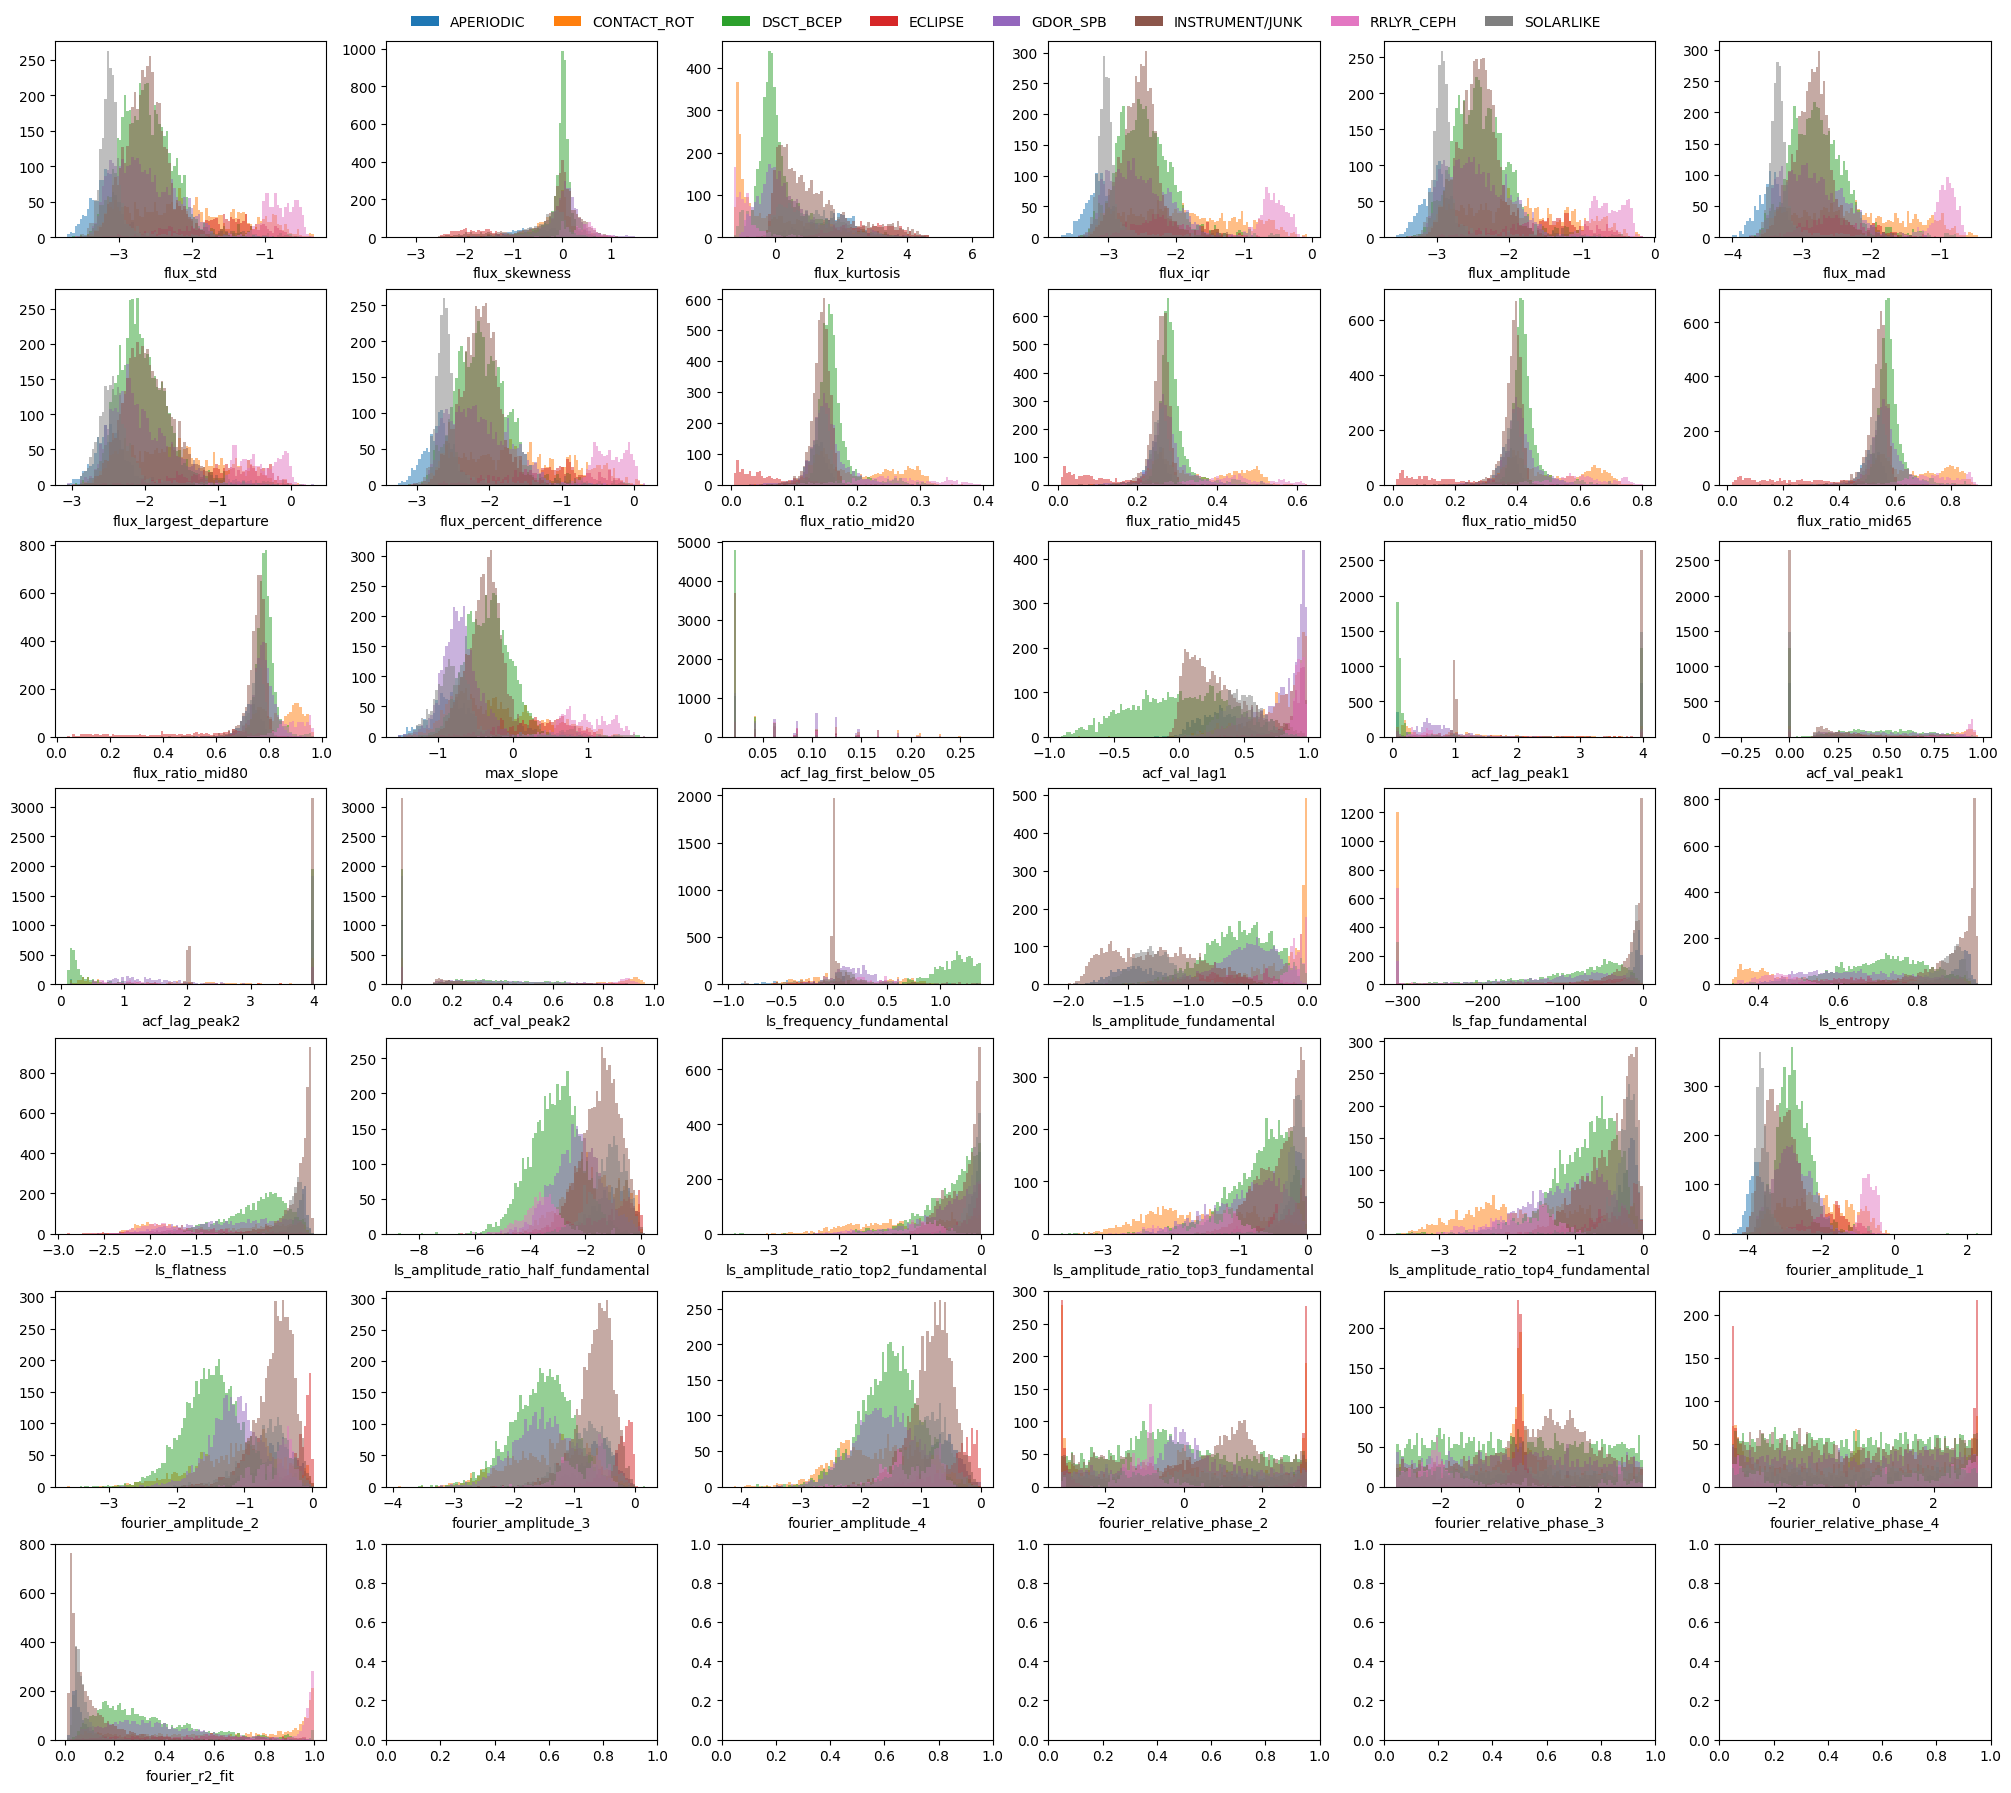

In [6]:
# Visualizing the features
bins = 100
n_rows = 7
fig, axs = plt.subplots(n_rows, 6, figsize=(20, 2.5*n_rows), constrained_layout=True)
for ax, col, col_name in zip(axs.ravel(), X_train.T, X_name):
    hrange = (np.amin(col), np.amax(col))
    for name in y_names:
        mask = y_train == name
        ax.hist(col[mask], range=hrange, bins=bins, label=name, alpha=0.5)
    ax.set_xlabel(col_name)

handles, labels = axs.ravel()[0].get_legend_handles_labels()
leg = fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02), frameon=False)
for h in leg.legend_handles:
    h.set_alpha(1.0)

In [7]:
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

corr = np.corrcoef(X_train, rowvar=False)
dist = 1 - np.abs(corr)
dist = 0.5 * (dist + dist.T)
np.fill_diagonal(dist, 0.0)

link = linkage(squareform(dist), method='average')
clusters = fcluster(link, t=0.01, criterion='distance') # 99% correlation

selected_features = []
for c in np.unique(clusters):
    idx = np.where(clusters == c)[0]
    print(c, [X_name[i].item() for i in idx])
    selected_features.append(idx[0]) # Choose first, how to best do this?
selected_features = np.sort(np.array(selected_features))

X_train = X_train[:, selected_features]
X_test  = X_test[:, selected_features]

with open(save_path / 'selected_features.pkl', "wb") as f:
    dump(selected_features, f, protocol=5)

1 ['acf_lag_first_below_05']
2 ['acf_val_lag1']
3 ['ls_frequency_fundamental']
4 ['acf_lag_peak1']
5 ['acf_lag_peak2']
6 ['flux_iqr', 'flux_mad']
7 ['flux_std', 'flux_amplitude', 'flux_percent_difference']
8 ['fourier_amplitude_1']
9 ['flux_largest_departure']
10 ['max_slope']
11 ['ls_amplitude_ratio_top3_fundamental']
12 ['ls_amplitude_ratio_top4_fundamental']
13 ['ls_amplitude_ratio_top2_fundamental']
14 ['acf_val_peak1']
15 ['acf_val_peak2']
16 ['ls_fap_fundamental']
17 ['fourier_r2_fit']
18 ['ls_entropy']
19 ['ls_flatness']
20 ['ls_amplitude_fundamental']
21 ['fourier_amplitude_3']
22 ['fourier_amplitude_4']
23 ['fourier_amplitude_2']
24 ['flux_ratio_mid45']
25 ['flux_ratio_mid50']
26 ['flux_ratio_mid20']
27 ['flux_ratio_mid65']
28 ['flux_ratio_mid80']
29 ['flux_skewness']
30 ['flux_kurtosis']
31 ['ls_amplitude_ratio_half_fundamental']
32 ['fourier_relative_phase_2']
33 ['fourier_relative_phase_3']
34 ['fourier_relative_phase_4']


## Classifiers

In [8]:
# Rescaling the features
from sklearn.preprocessing import QuantileTransformer, StandardScaler, RobustScaler, LabelEncoder

scaler = RobustScaler()
X_train_pre = scaler.fit_transform(X_train)
X_test_pre = scaler.transform(X_test)
le = LabelEncoder().fit(y_train)

with open(save_path / 'preprocessor.pkl', "wb") as f:
    dump(scaler, f, protocol=5)

with open(save_path / 'label_encoder.pkl', "wb") as f:
    dump(le, f, protocol=5)

### K-nn

In [9]:
# k-nn classifier, macro f1 record: 0.843

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedGroupKFold

train_groups = np.array([int(p.split('-')[2]) for p in path_train])
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1234)

clf = GridSearchCV(
    KNeighborsClassifier(n_jobs=1), cv=cv, scoring='f1_macro', n_jobs=4,
    param_grid={'n_neighbors': [15, 25], 'weights': ['uniform', 'distance']}
)
clf.fit(X_train_pre, le.transform(y_train), groups=train_groups)
print(classification_report(y_true=y_test, y_pred=le.inverse_transform(clf.predict(X_test_pre)), digits=3))

                 precision    recall  f1-score   support

      APERIODIC      0.783     0.637     0.703       317
    CONTACT_ROT      0.951     0.657     0.777       708
      DSCT_BCEP      0.935     0.952     0.943      1233
        ECLIPSE      0.972     0.847     0.905       242
       GDOR_SPB      0.799     0.837     0.818       843
INSTRUMENT/JUNK      0.838     0.931     0.882      1075
     RRLYR_CEPH      0.959     0.977     0.968       214
      SOLARLIKE      0.680     0.836     0.750       529

       accuracy                          0.853      5161
      macro avg      0.864     0.834     0.843      5161
   weighted avg      0.862     0.853     0.852      5161



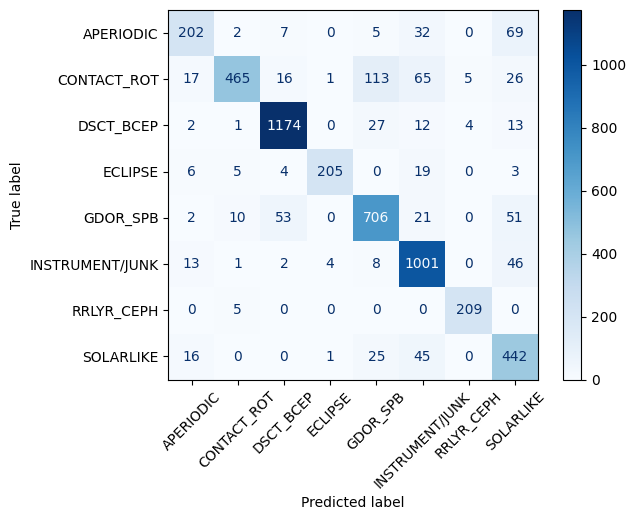

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

y_test_pred = le.inverse_transform(clf.predict(X_test_pre))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45)

In [11]:
# Best hyperparameters 
pl.DataFrame(clf.cv_results_).sort('rank_test_score').drop(['^.*_time$', 'params'])

param_n_neighbors,param_weights,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
i64,str,f64,f64,f64,f64,f64,f64,f64,i32
15,"""distance""",0.833526,0.826082,0.819685,0.832084,0.83743,0.829761,0.00622,1
15,"""uniform""",0.835574,0.826069,0.81727,0.832679,0.834791,0.829276,0.006872,2
25,"""distance""",0.833471,0.827596,0.811827,0.827178,0.829528,0.82592,0.00739,3
25,"""uniform""",0.834293,0.827566,0.811694,0.82504,0.82811,0.825341,0.007471,4


### Random Forest

In [12]:
%%time

# Random Forest, macro f1 record: 0.907 3m on 32 grid jobs
from sklearn.ensemble import RandomForestClassifier

param_grid={
    "n_estimators": [300, 600],
    "max_depth": [10, 20],
    "min_samples_leaf": [1, 2, 5],
    "max_features": [int(np.sqrt(X_train.shape[1])), 0.3, 0.6], # sqrt is default
    #"class_weight": ["balanced", None],
}
base_estimator = RandomForestClassifier(n_jobs=8, random_state=1234, class_weight='balanced')
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1234)
clf = GridSearchCV(estimator=base_estimator, param_grid=param_grid, n_jobs=4, cv=cv, scoring='f1_macro', verbose=1)

clf.fit(X_train_pre, le.transform(y_train), groups=train_groups)
print(classification_report(y_true=y_test, y_pred=le.inverse_transform(clf.predict(X_test_pre)), digits=3))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
                 precision    recall  f1-score   support

      APERIODIC      0.783     0.798     0.791       317
    CONTACT_ROT      0.904     0.840     0.871       708
      DSCT_BCEP      0.982     0.977     0.980      1233
        ECLIPSE      0.987     0.917     0.951       242
       GDOR_SPB      0.903     0.921     0.912       843
INSTRUMENT/JUNK      0.914     0.964     0.938      1075
     RRLYR_CEPH      0.985     0.935     0.959       214
      SOLARLIKE      0.833     0.837     0.835       529

       accuracy                          0.916      5161
      macro avg      0.911     0.899     0.905      5161
   weighted avg      0.917     0.916     0.916      5161

CPU times: user 1min 9s, sys: 381 ms, total: 1min 9s
Wall time: 9min 12s


In [13]:
# Best hyperparameters
pl.DataFrame(clf.cv_results_, strict=False).sort('rank_test_score').drop(['^.*_time$', 'params']).head(10)

param_max_depth,param_max_features,param_min_samples_leaf,param_n_estimators,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
i64,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,i32
20,0.3,1,300,0.902765,0.876176,0.893925,0.889825,0.884576,0.889453,0.008915,1
20,0.3,2,600,0.901441,0.878208,0.893682,0.889853,0.882993,0.889235,0.00812,2
20,0.3,1,600,0.902188,0.875382,0.893634,0.890447,0.884287,0.889187,0.009,3
20,0.3,2,300,0.901823,0.878154,0.893724,0.888936,0.879237,0.888375,0.008919,4
20,0.6,2,300,0.899736,0.873349,0.892167,0.893644,0.877326,0.887244,0.010126,5
20,0.6,2,600,0.900676,0.873184,0.89242,0.891737,0.877817,0.887167,0.010138,6
20,5.0,1,600,0.899176,0.875041,0.890134,0.888274,0.881439,0.886813,0.008167,7
20,0.6,1,300,0.900448,0.872061,0.888355,0.891639,0.880941,0.886689,0.009629,8
20,0.6,1,600,0.898521,0.870817,0.890657,0.891095,0.881572,0.886532,0.00952,9


Text(0.5, 1.0, 'Full dataset')

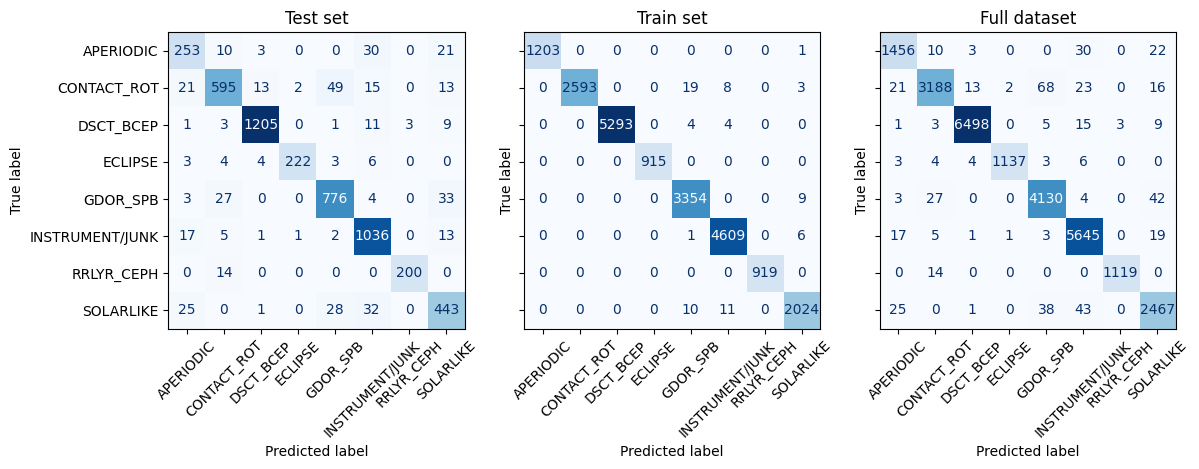

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
y_test_pred = le.inverse_transform(clf.predict(X_test_pre))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[0], colorbar=False)
axs[0].set_title('Test set')
y_train_pred = le.inverse_transform(clf.predict(X_train_pre))
ConfusionMatrixDisplay.from_predictions(y_true=y_train, y_pred=y_train_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[1], colorbar=False)
axs[1].set_title('Train set')
ConfusionMatrixDisplay.from_predictions(y_true=np.concatenate([y_train, y_test]), y_pred=np.concatenate([y_train_pred, y_test_pred], axis=0), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[2], colorbar=False)
axs[2].set_title('Full dataset')

Text(0.5, 1.0, 'Random Forest Mean Decrease in Impurity')

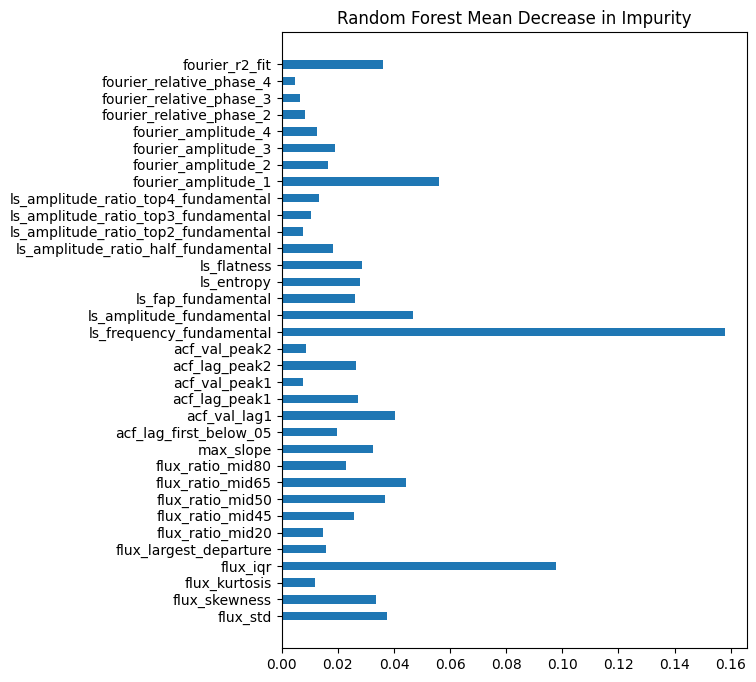

In [16]:
fig, ax = plt.subplots(figsize=(6, 8))

#RF MDI has a few drabacks
# Biased toward high-cardinality or continuous features (i.e. features with many possible split points are favored)
# Inflated importance for correlated predictors.
# It is a training-set measure. It does not evaluate generalization impact.

ax.barh(X_name[selected_features], clf.best_estimator_.feature_importances_, height=0.5)
ax.set_title('Random Forest Mean Decrease in Impurity')

## XGBOOST

In [17]:
%%time

# XGBoost, macro f1 record: 0.917 
from xgboost import XGBClassifier

xgb = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=8,
    random_state=1234
)

param_grid = {
    "n_estimators": [150, 300], 
    "max_depth": [2, 3, 5],
    "min_child_weight": [3, 5],
    "gamma": [0.1, 0.5, 1.0],
    "learning_rate": [0.1, 0.3],
    "subsample": [0.75],
    #"colsample_bytree": [0.7, 0.9, 1.0],
    #"reg_lambda": [0.0, 1.0, 5.0],
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1234)

clf = GridSearchCV(estimator=xgb, param_grid=param_grid, scoring="f1_macro", cv=cv, n_jobs=4, verbose=1)
clf.fit(X_train_pre, le.transform(y_train), groups=train_groups)
print(classification_report(y_true=y_test, y_pred=le.inverse_transform(clf.predict(X_test_pre)), digits=3))

Fitting 5 folds for each of 72 candidates, totalling 360 fits
                 precision    recall  f1-score   support

      APERIODIC      0.863     0.792     0.826       317
    CONTACT_ROT      0.909     0.856     0.881       708
      DSCT_BCEP      0.973     0.979     0.976      1233
        ECLIPSE      0.983     0.942     0.962       242
       GDOR_SPB      0.905     0.912     0.908       843
INSTRUMENT/JUNK      0.929     0.955     0.942      1075
     RRLYR_CEPH      0.977     0.981     0.979       214
      SOLARLIKE      0.825     0.873     0.848       529

       accuracy                          0.922      5161
      macro avg      0.920     0.911     0.915      5161
   weighted avg      0.922     0.922     0.922      5161

CPU times: user 33.9 s, sys: 240 ms, total: 34.2 s
Wall time: 3min 19s


In [18]:
# Best hyperparameters
pl.DataFrame(clf.cv_results_, strict=False).sort('rank_test_score').drop(['^.*_time$', 'params']).head(10)

param_gamma,param_learning_rate,param_max_depth,param_min_child_weight,param_n_estimators,param_subsample,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
f64,f64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,i32
0.1,0.1,5,3,300,0.75,0.920419,0.901195,0.908259,0.903131,0.896581,0.905917,0.008161,1
0.1,0.1,5,5,300,0.75,0.919124,0.90024,0.909037,0.900725,0.898165,0.905458,0.007777,2
0.5,0.1,5,5,300,0.75,0.920201,0.898141,0.907664,0.899441,0.896563,0.904402,0.008781,3
0.1,0.3,3,3,300,0.75,0.918067,0.898554,0.904276,0.896782,0.901376,0.903811,0.007569,4
0.5,0.1,5,3,300,0.75,0.921141,0.899085,0.905761,0.898249,0.894784,0.903804,0.009369,5
0.5,0.1,5,3,150,0.75,0.920322,0.896576,0.90771,0.898507,0.895365,0.903696,0.009376,6
0.1,0.3,5,3,150,0.75,0.918367,0.896165,0.907387,0.899868,0.896417,0.903641,0.008405,7
0.5,0.3,2,3,300,0.75,0.913983,0.899109,0.908467,0.901371,0.895266,0.903639,0.006724,8
0.1,0.3,5,5,150,0.75,0.916208,0.897519,0.90828,0.899085,0.896695,0.903557,0.007562,9


Text(0.5, 1.0, 'Full dataset')

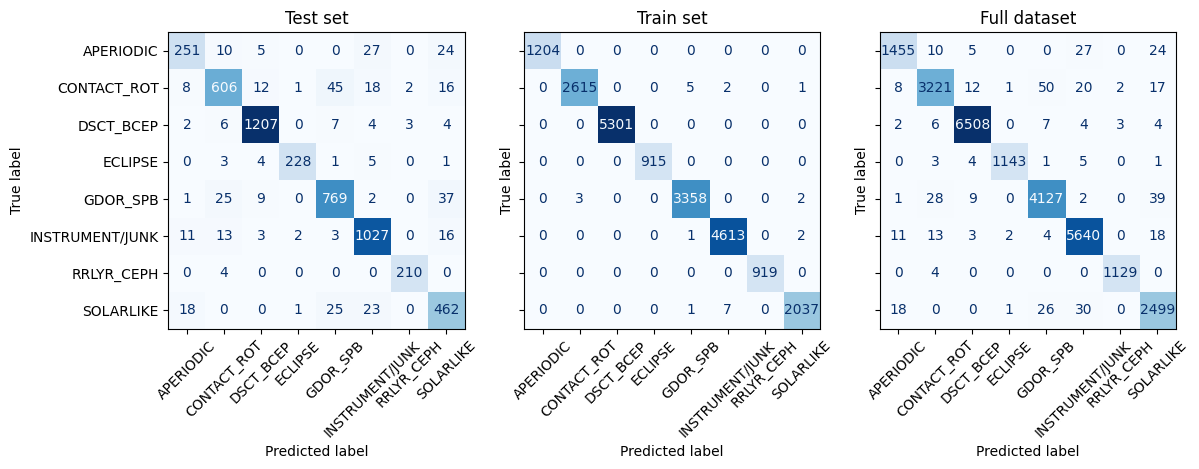

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
y_test_pred = le.inverse_transform(clf.predict(X_test_pre))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred=y_test_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[0], colorbar=False)
axs[0].set_title('Test set')
y_train_pred = le.inverse_transform(clf.predict(X_train_pre))
ConfusionMatrixDisplay.from_predictions(y_true=y_train, y_pred=y_train_pred, cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[1], colorbar=False)
axs[1].set_title('Train set')
ConfusionMatrixDisplay.from_predictions(y_true=np.concatenate([y_train, y_test]), y_pred=np.concatenate([y_train_pred, y_test_pred], axis=0), cmap=plt.cm.Blues, xticks_rotation=45, ax=axs[2], colorbar=False)
axs[2].set_title('Full dataset')

CPU times: user 3.07 s, sys: 174 ms, total: 3.25 s
Wall time: 16.1 s


Text(0.5, 1.0, 'Random Forest, Permutation importance')

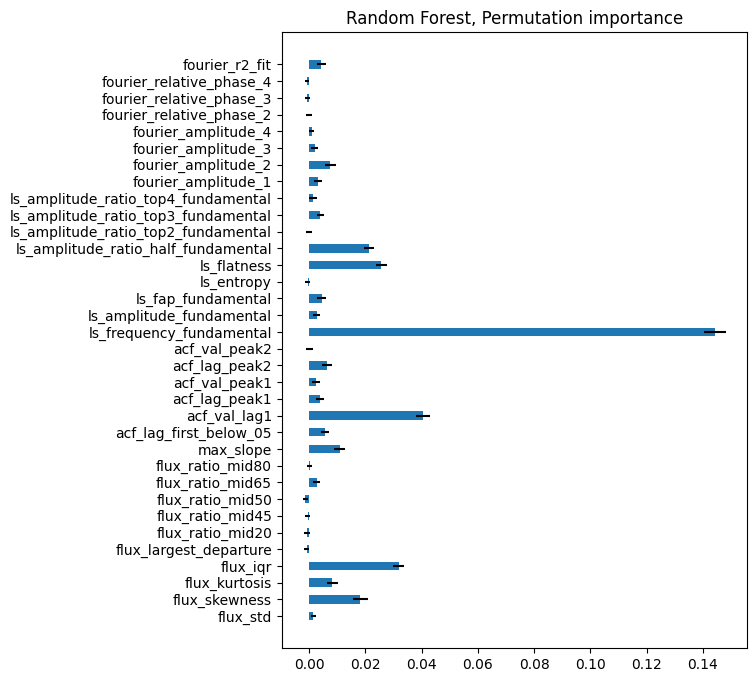

In [20]:
%%time
from sklearn.inspection import permutation_importance

# Permutation importance drawbacks:
# Underestimates importance under feature correlation.
# If two features encode the same information, permuting one may not hurt performance.

pi_global = permutation_importance(clf.best_estimator_, X_test_pre, le.transform(y_test), scoring="f1_macro", n_repeats=30, random_state=0, n_jobs=16)

fig, ax = plt.subplots(figsize=(6, 8))
ax.barh(y=np.array(X_name)[np.array(selected_features)], width=pi_global.importances_mean, xerr=pi_global.importances_std, height=0.5)
ax.set_title('Permutation-based feature importance')

CPU times: user 3.76 s, sys: 92.2 ms, total: 3.85 s
Wall time: 11.5 s


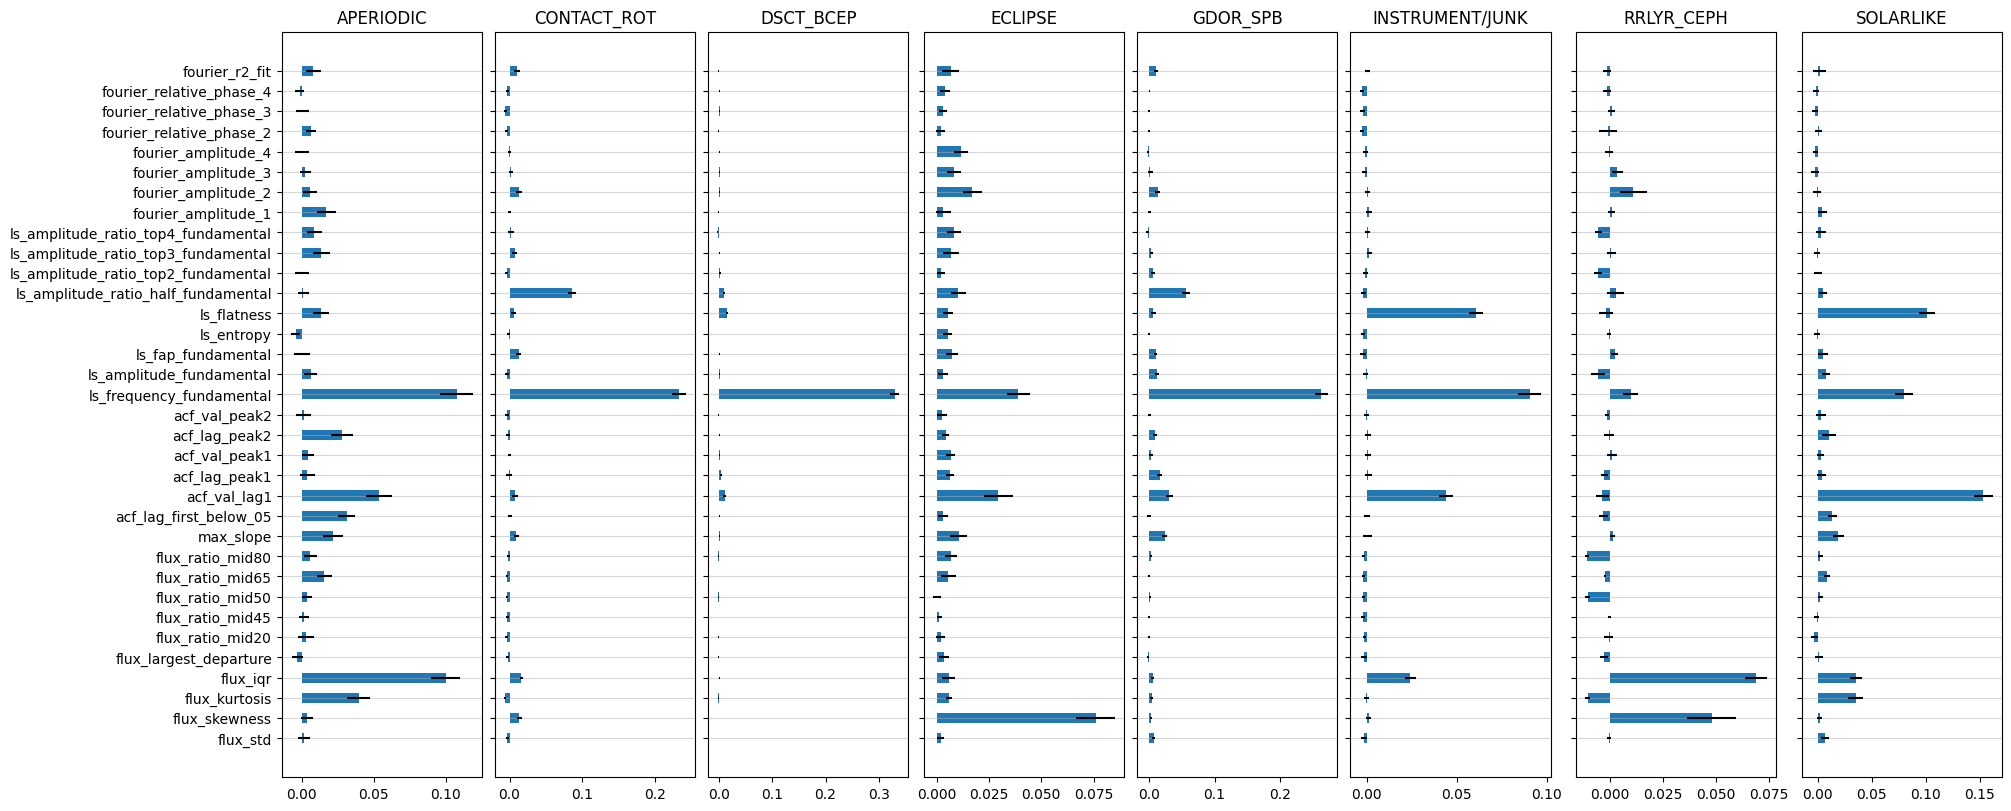

In [21]:
%%time
from sklearn.metrics import f1_score

best_clf = clf.best_estimator_
classes = np.unique(le.transform(y_test))

def per_class_f1_scorer(estimator, X, y):
    y_pred = estimator.predict(X)
    return np.array([f1_score(y == c, y_pred == c, zero_division=0) for c in classes], dtype=float)

pi_class = permutation_importance(best_clf, X_test_pre, le.transform(y_test), scoring=per_class_f1_scorer, n_repeats=30, random_state=0, n_jobs=16)

fig, axs = plt.subplots(1, len(classes), figsize=(20, 8), sharey=True, constrained_layout=True)
for ax, name, pi_class_mean, pi_class_std in zip(axs, classes, pi_class.importances_mean.T, pi_class.importances_std.T):
    ax.barh(y=np.array(X_name)[np.array(selected_features)], width=pi_class_mean, xerr=pi_class_std, height=0.5)
    ax.set_title(le.inverse_transform([name]).item())
    ax.grid(axis='y', alpha=0.5)

## Calibration

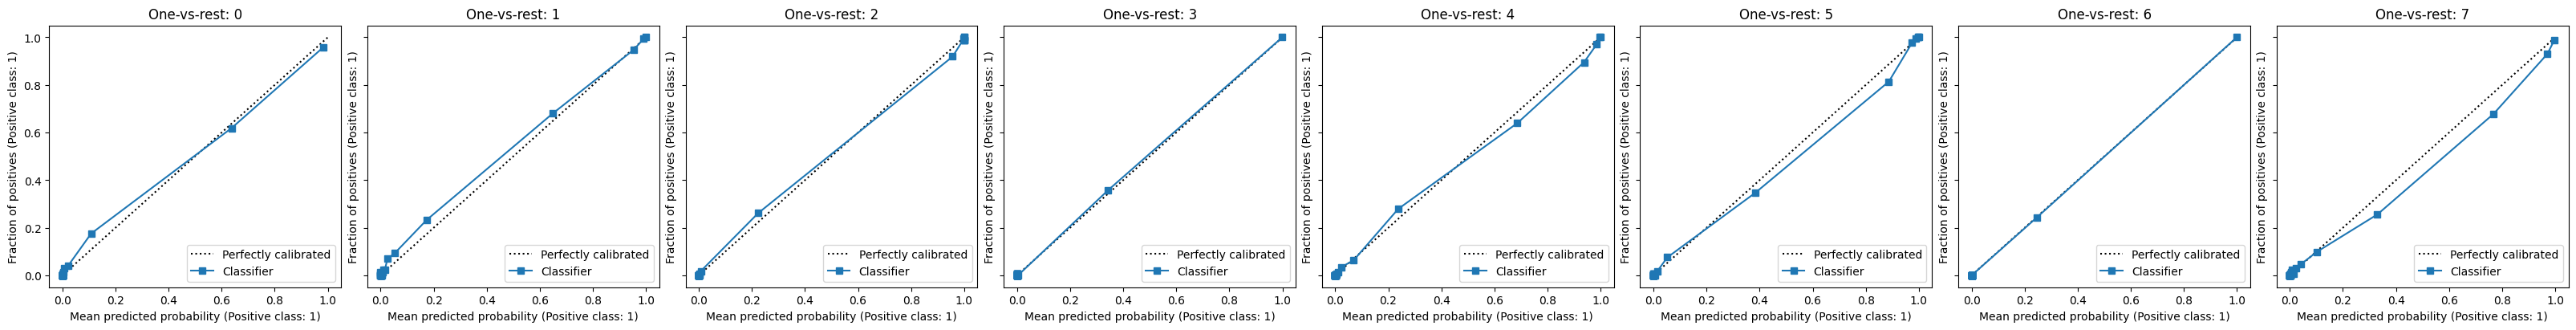

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

est = clf.best_estimator_
proba = est.predict_proba(X_test_pre)
classes = est.classes_
fig, axs = plt.subplots(1, len(classes), figsize=(4*len(classes), 4), sharey=True, constrained_layout=True)

for ax, c in zip(np.atleast_1d(axs), classes):
    k = np.where(classes == c)[0][0]
    y_bin = (le.transform(y_test) == c).astype(int)
    p_c = proba[:, k]
    CalibrationDisplay.from_predictions(y_true=y_bin, y_prob=p_c, n_bins=30, strategy="quantile", ax=ax)
    ax.set_title(f"One-vs-rest: {c}")

## Export

In [29]:
paths_all = np.concatenate([path_train, path_test])
y_all = np.concatenate([y_train, y_test])
X_all = np.concatenate([X_train_pre, X_test_pre], axis=0)

In [38]:
from training import prepare_predictions_dataframe

df_pred = prepare_predictions_dataframe(clf.best_estimator_, le, X_preprocessed=X_all, paths=paths_all, drop_nans=True)
display(df_pred.head())
df_pred.write_parquet(save_path / 'predictions.parquet')

with open(save_path / 'model.pkl', "wb") as f:
    dump(clf.best_estimator_, f, protocol=5)

path,APERIODIC,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENT/JUNK,RRLYR_CEPH,SOLARLIKE,best_rf_class,rf_entropy,best_rf_proba
str,f32,f32,f32,f32,f32,f32,f32,f32,str,f64,f32
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000375,0.00664,0.000045,0.000081,0.008243,0.982678,0.000009,0.001928,"""INSTRUMENT/JUNK""",0.051144,0.982678
"""/STER/mamsie/tess/TIC/tglc_scr…",0.005536,0.000425,0.000061,0.000009,0.000744,0.000506,0.000004,0.992716,"""SOLARLIKE""",0.023691,0.992716
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000154,0.000771,0.998956,0.000004,0.000068,0.000016,0.000002,0.00003,"""DSCT_BCEP""",0.004392,0.998956
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000032,0.983183,0.000227,0.000155,0.012708,0.001946,0.000261,0.001487,"""CONTACT_ROT""",0.047965,0.983183
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000148,0.001811,0.907923,0.001159,0.00379,0.083499,0.00002,0.001651,"""DSCT_BCEP""",0.167122,0.907923


## Visualization of feature space

CPU times: user 2min 16s, sys: 992 ms, total: 2min 17s
Wall time: 44.9 s


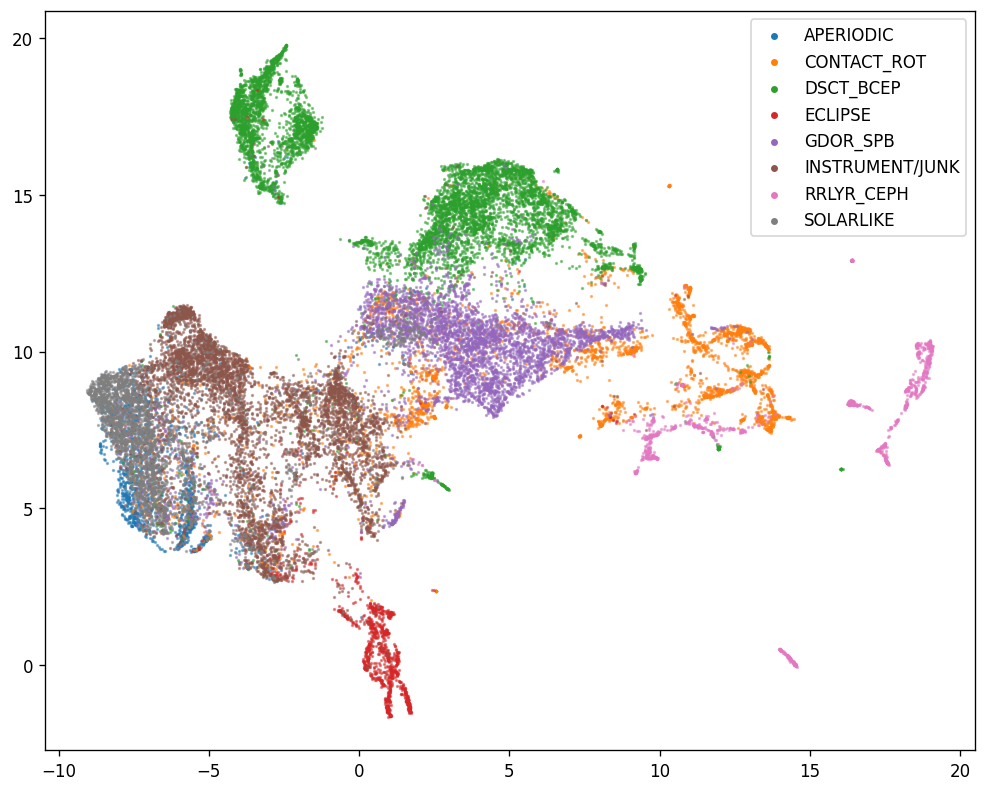

In [39]:
%%time
from umap import UMAP

projector = UMAP(n_components=2, min_dist=0.1, negative_sample_rate=10, metric='euclidean', n_jobs=8, n_neighbors=25)
X_proj = projector.fit_transform(X_all)
fig, ax = plt.subplots(figsize=(10, 8), dpi=120)

for name in y_names:
    mask = y_all == name
    ax.scatter(X_proj[mask, 0], X_proj[mask, 1], s=1, label=name, alpha=0.5)
leg = plt.legend()
for lh in leg.legend_handles:
    lh.set_alpha(1)
    lh._sizes = [10]

In [41]:
df_hv = pl.DataFrame({'lambda_1': X_proj[:, 0], 'lambda_2': X_proj[:, 1], 'class': y_all, 'path': paths_all})
df_hv = df_hv.join(df_training_features.select(['path', 'GaiaID', 'ls_frequency_fundamental']), on='path')
df_hv.write_parquet('viz.parquet')

## Error analysis

In [45]:
df_pred.join(df_training_set.select(['path','label']), on='path')

path,APERIODIC,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENT/JUNK,RRLYR_CEPH,SOLARLIKE,best_rf_class,rf_entropy,best_rf_proba,label
str,f32,f32,f32,f32,f32,f32,f32,f32,str,f64,f32,str
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000684,0.95927,0.000064,0.000235,0.037866,0.000188,0.000007,0.001686,"""CONTACT_ROT""",0.088425,0.95927,"""CONTACT_ROT"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000375,0.00664,0.000045,0.000081,0.008243,0.982678,0.000009,0.001928,"""INSTRUMENT/JUNK""",0.051144,0.982678,"""INSTRUMENT/JUNK"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.005536,0.000425,0.000061,0.000009,0.000744,0.000506,0.000004,0.992716,"""SOLARLIKE""",0.023691,0.992716,"""SOLARLIKE"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000154,0.000771,0.998956,0.000004,0.000068,0.000016,0.000002,0.00003,"""DSCT_BCEP""",0.004392,0.998956,"""DSCT_BCEP"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000001,0.000079,0.000059,0.000005,0.999837,0.000008,0.000006,0.000005,"""GDOR_SPB""",0.000858,0.999837,"""GDOR_SPB"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000001,0.004757,0.000004,0.000008,0.000055,0.000008,0.995149,0.000018,"""RRLYR_CEPH""",0.015038,0.995149,"""RRLYR_CEPH"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000001,0.000771,0.000004,0.000005,0.000065,0.000016,0.999081,0.000056,"""RRLYR_CEPH""",0.003816,0.999081,"""RRLYR_CEPH"""
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000005,0.001741,0.00003,0.000012,0.003642,0.000047,0.994447,0.000077,"""RRLYR_CEPH""",0.018636,0.994447,"""RRLYR_CEPH"""


2


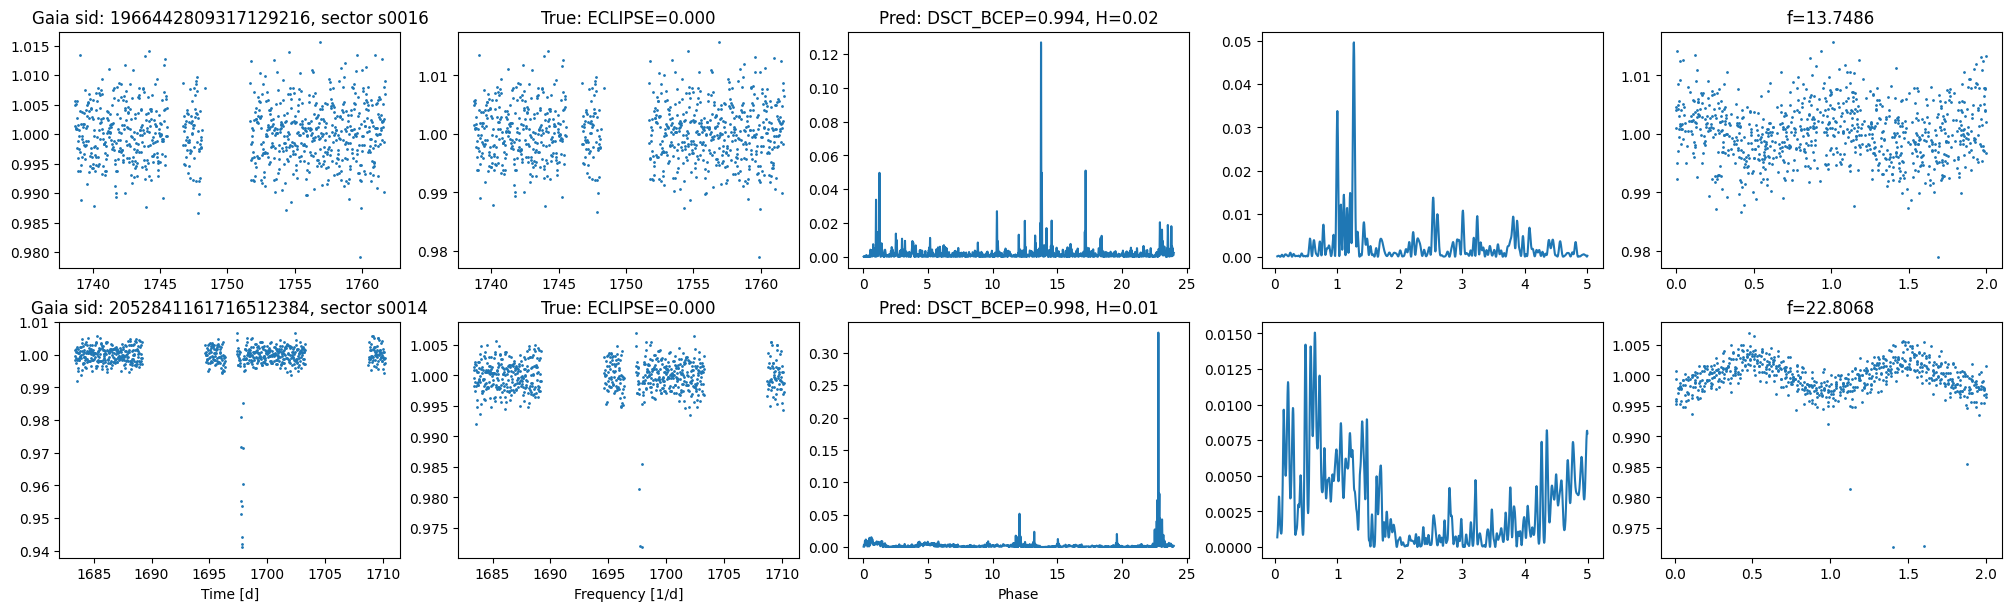

In [48]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from light_curves import read_fits_lc, preprocess_lc
from frequency_domain_features import compute_lombscargle_periodogram

true_class = 'INSTRUMENT/JUNK'
true_class = 'APERIODIC'
true_class = 'ECLIPSE'
#true_class = 'CONTACT_ROT'
#pred_class = 'CONTACT_ROT'
#pred_class = 'INSTRUMENT/JUNK'
#pred_class = 'GDOR_SPB'
#pred_class = 'CONTACT_ROT'
pred_class = 'DSCT_BCEP'

df_analysis = df_pred.join(df_training_set.select(['path','label']), on='path').filter(
    pl.col('label').eq(true_class) & pl.col('best_rf_class').eq(pred_class)
).with_columns(
    pl.col('path').str.split('-').list.get(2).alias('sid'),
    pl.col('path').str.split('-').list.get(3).alias('sector')
).sort(['sid', 'sector']).unique('sid')
print(df_analysis.height)

fig, axs = plt.subplots(max(2, df_analysis.height), 5, figsize=(20, 3*df_analysis.height), constrained_layout=True, sharex=False)
for row, ax in zip(df_analysis.iter_rows(named=True), axs):
    path_, proba, entropy, proba_true = row['path'], row[pred_class], row['rf_entropy'], row[true_class]
    sid, sector = path_.split('-')[2:4]
    ax[0].set_title(f"Gaia sid: {sid}, sector {sector}")
    ax[1].set_title(f"True: {true_class}={proba_true:0.3f}")
    ax[2].set_title(f"Pred: {pred_class}={proba:0.3f}, H={entropy:0.2f}")
    time, flux, sector = read_fits_lc(path_)
    ax[0].scatter(time, flux, s=1)
    time, flux = preprocess_lc(time, flux, sector)
    freq, ampl, _ = compute_lombscargle_periodogram(time, flux)
    best_freq = freq[np.argmax(ampl)]
    ax[1].scatter(time, flux, s=1)
    ax[2].plot(freq, ampl)
    ax[4].set_title(f"f={best_freq:0.4f}")
    ax[4].scatter(np.mod(time, 2/best_freq)*best_freq, flux, s=1)
    ax[3].plot(freq[freq<5], ampl[freq<5])
ax[0].set_xlabel('Time [d]')
ax[1].set_xlabel('Frequency [1/d]')
ax[2].set_xlabel('Phase');

# Pathological cases

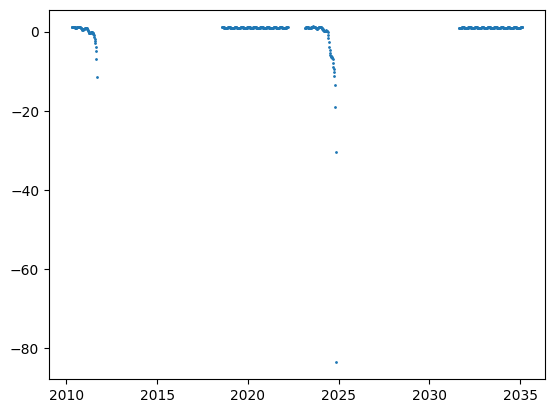

In [51]:
# Light curve completely filtered by outlier processing
from light_curves import read_fits_lc

time, flux, sector = read_fits_lc(
    '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0026/cam1-ccd1/0020/9288/9154/7721/hlsp_tglc_tess_ffi_gaiaid-2092889154772199168-s0026-cam1-ccd1_tess_v1_llc.fits',
)
plt.scatter(time, flux, s=1)


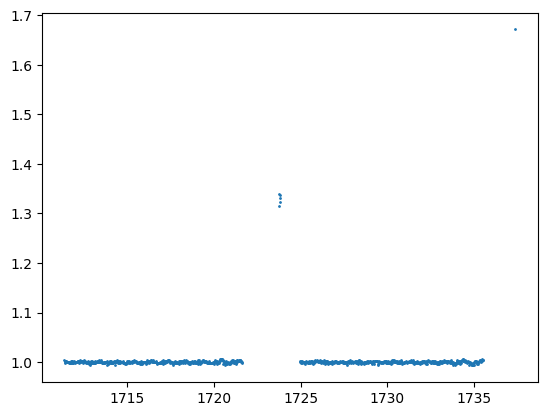

In [52]:
# Examples of extreme kurtosis

time, flux, sector = read_fits_lc(
    '/STER/mamsie/tess/TIC/tglc_scripts_plato_mit/s0015/cam4-ccd4/0015/5667/2589/6237/hlsp_tglc_tess_ffi_gaiaid-1556672589623717632-s0015-cam4-ccd4_tess_v1_llc.fits',
)
plt.scatter(time, flux, s=1)

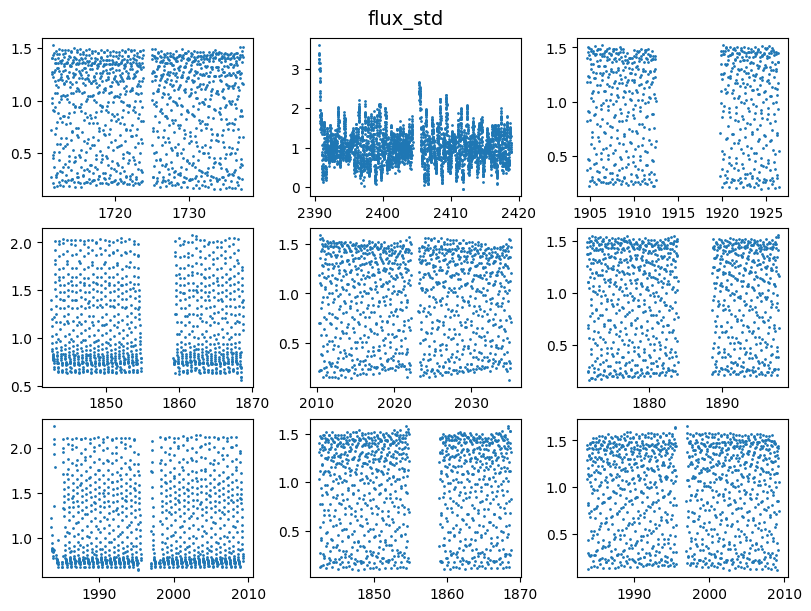

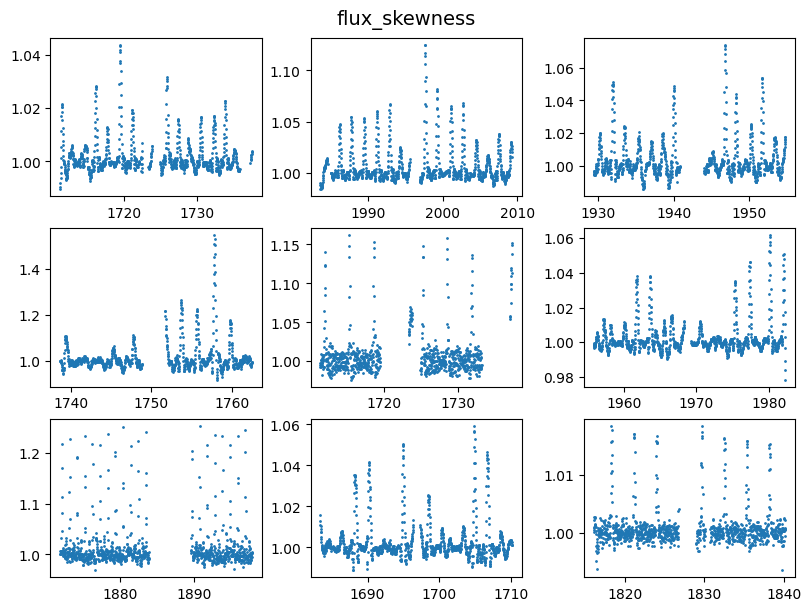

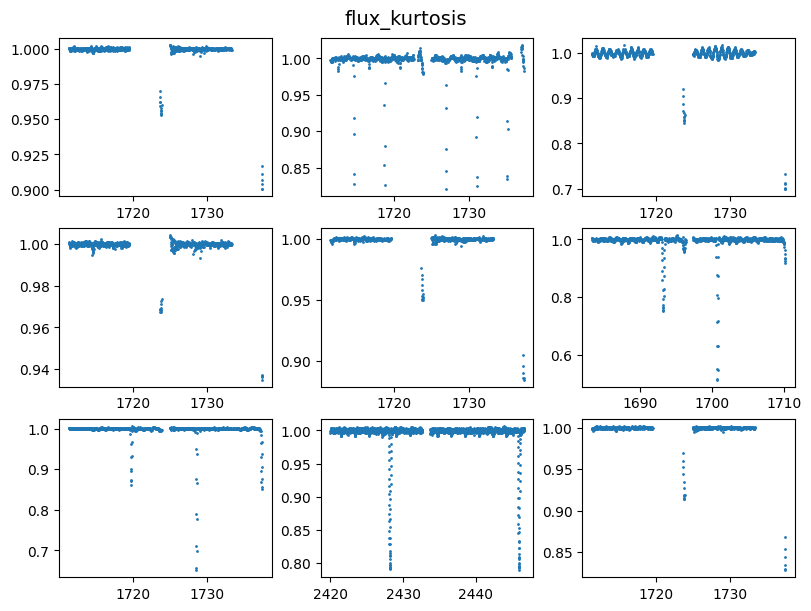

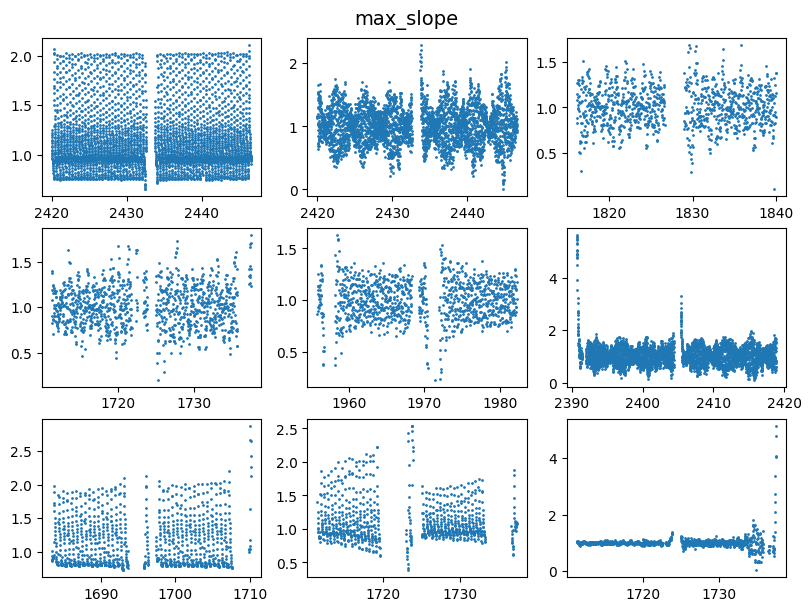

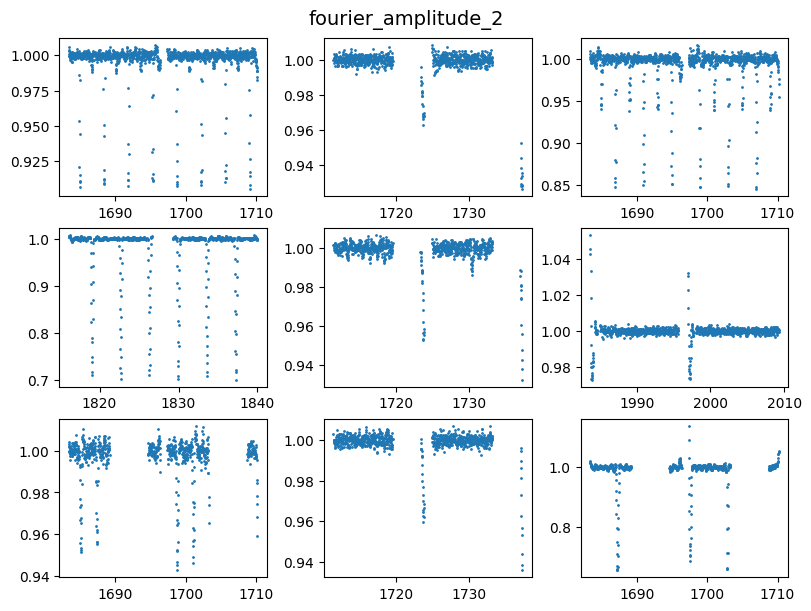

In [53]:
# Examples of light curve with extreme values of certain features

extreme_cols = ['flux_std', 'flux_skewness', 'flux_kurtosis', 'max_slope', 'fourier_amplitude_2']
for col in extreme_cols:
    fig, axs = plt.subplots(3, 3, figsize=(8, 6), constrained_layout=True)
    for path, ax in zip(df_training_features.sort(col).tail(9)['path'].to_list(), axs.ravel()):
        time, flux, _ = read_fits_lc(path)
        ax.scatter(time, flux, s=1)
    fig.suptitle(col, fontsize=14)

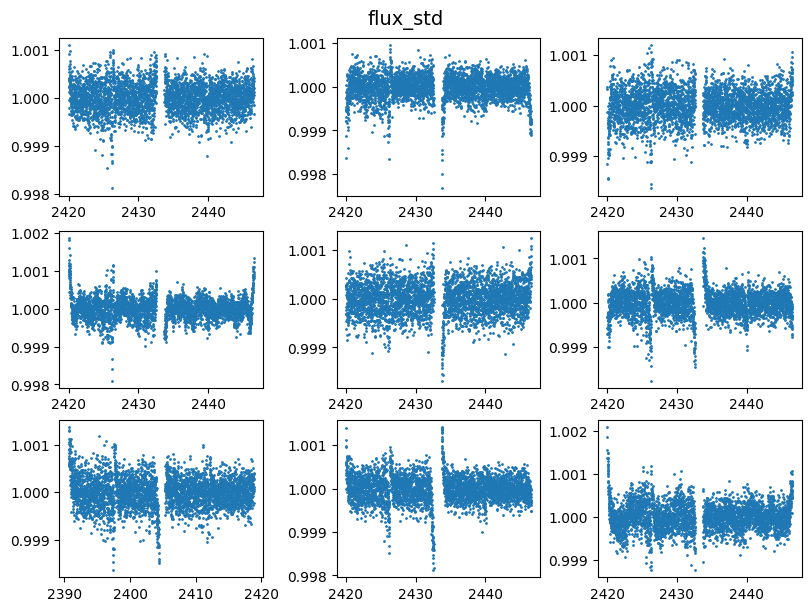

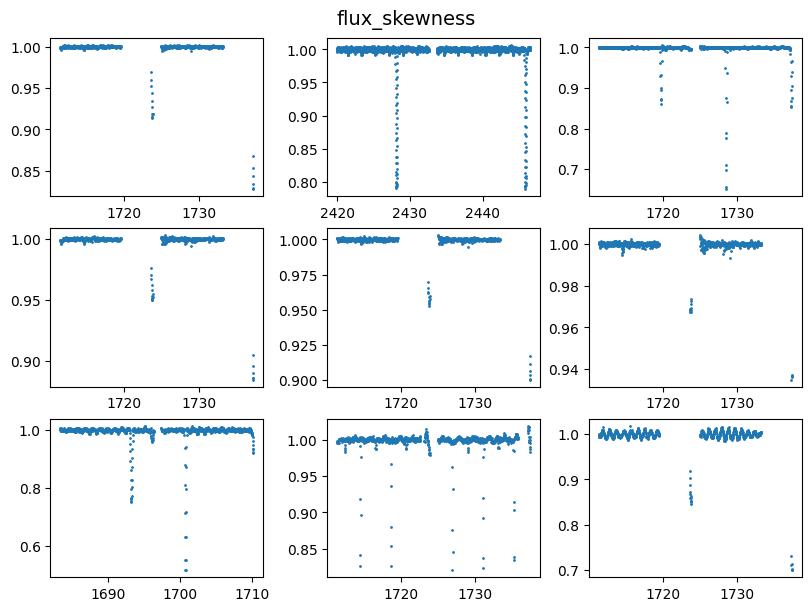

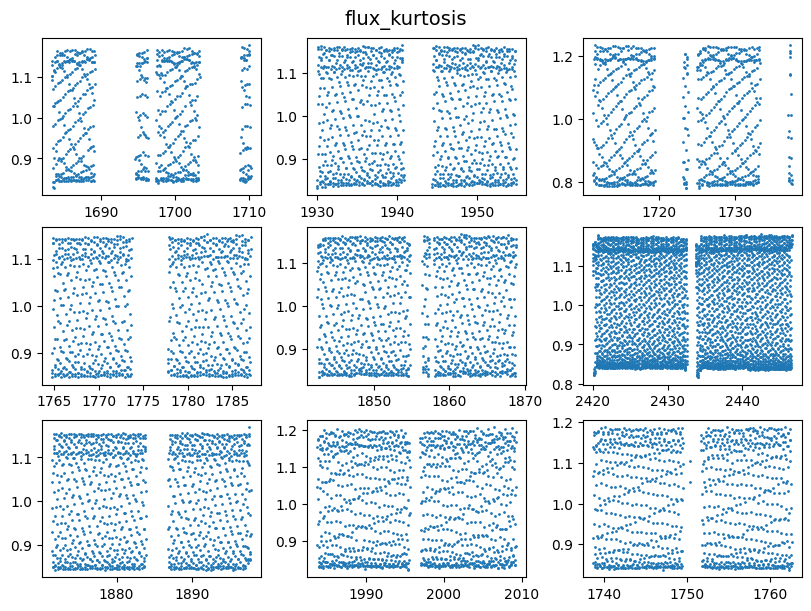

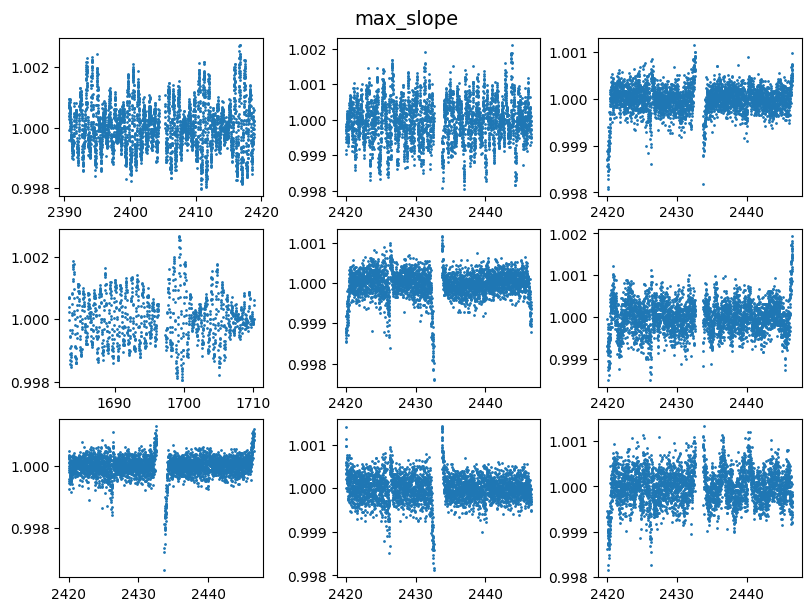

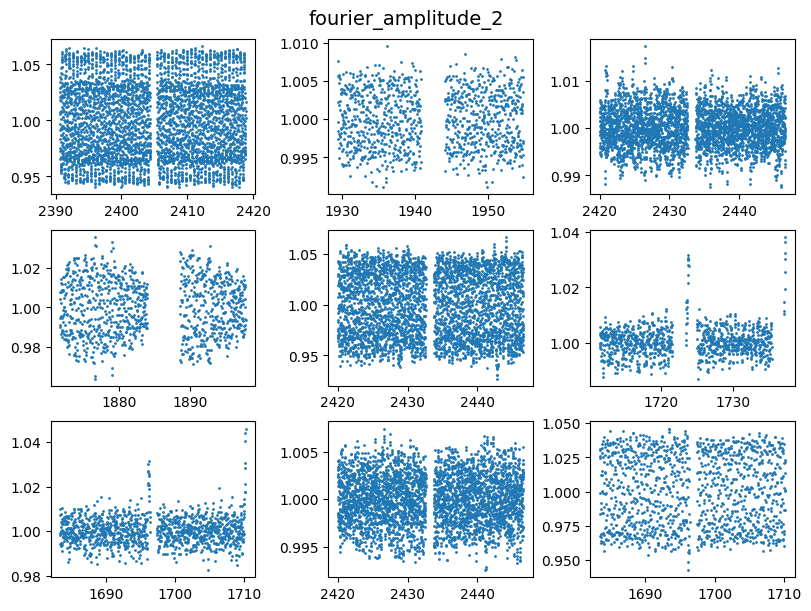

In [55]:
# Examples of light curve with extreme values of certain features

extreme_cols = ['flux_std', 'flux_skewness', 'flux_kurtosis', 'max_slope', 'fourier_amplitude_2']
for col in extreme_cols:
    fig, axs = plt.subplots(3, 3, figsize=(8, 6), constrained_layout=True)
    for path, ax in zip(df_training_features.sort(col).head(9)['path'].to_list(), axs.ravel()):
        time, flux, _ = read_fits_lc(path)
        ax.scatter(time, flux, s=1)
    fig.suptitle(col, fontsize=14)